# 01. 원본 데이터 전처리 (UCI 유압 시스템)

UCI 원본(`data/raw/`)을 분석용 CSV(`data/processed/`)로 바꾸는 노트북입니다. 이전에 쓰던 `make_csv.py`를 단계별로 풀어 쓴 것입니다.

**이 노트북의 처리 방식은 초안입니다.** 5절 "처리"의 각 셀에 붙은 **[검토]** 항목을 보고, 수업에서 배운 방법(G-1)에 맞게 바꿔 주세요. 처리를 바꾸면 이 노트북을 처음부터 다시 실행해서 CSV를 새로 저장합니다.

| 순서 | 내용 | G-1 근거 |
| --- | --- | --- |
| 1 | 설정과 경로 | |
| 2 | 라벨 읽기와 구조 확인 | 12단원 `head`/`info`/`value_counts` |
| 3 | 센서 읽기와 크기 확인 | 6\~8단원 파일 입출력, 10단원 shape |
| 4 | 품질 진단: 위장 결측, 포화, 파생값, 안정 구간 | 15\~16단원, 2일차 센서 함정 |
| 5 | 처리 **(초안)** | 15단원 결측 처리, 2일차 포화 표시 |
| 6 | 특징 추출: 사이클별 통계 | 12\~14단원 집계 |
| 7 | 검증 | 3절 "단계 전후 건수 대조" |
| 8 | 저장 | 3절 "원본은 그대로, 새 파일에 저장" |

**실행 전 준비**: 원본을 `data/raw/`에 받아 둡니다(루트 README 3절). 패키지는 `pip install -r ml/requirements.txt`로 설치합니다. 센서 파일 읽기에 몇 분 걸립니다.

## 1. 설정과 경로

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 노트북을 어느 폴더에서 열어도 저장소 루트를 찾도록 합니다
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "ml").is_dir())
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

from matplotlib import font_manager

# 한글 글꼴: 설치된 것 중 처음 찾은 것을 씁니다 (Windows, macOS, Linux 순)
installed = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic"] if f in installed), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 30)

print("원본 폴더:", RAW)
print("원본 파일 수:", len(list(RAW.glob("*.txt"))), "(20개여야 함)")

원본 폴더: C:\Gorosteel\data\raw
원본 파일 수: 20 (20개여야 함)


In [2]:
# 센서 사전: 이름 -> (물리량, 단위, 샘플링 Hz). 출처: data/raw/description.txt
SENSORS = {
    "PS1": ("압력", "bar", 100), "PS2": ("압력", "bar", 100), "PS3": ("압력", "bar", 100),
    "PS4": ("압력", "bar", 100), "PS5": ("압력", "bar", 100), "PS6": ("압력", "bar", 100),
    "EPS1": ("모터 전력", "W", 100), "FS1": ("유량", "l/min", 10), "FS2": ("유량", "l/min", 10),
    "TS1": ("온도", "°C", 1), "TS2": ("온도", "°C", 1), "TS3": ("온도", "°C", 1), "TS4": ("온도", "°C", 1),
    "VS1": ("진동", "mm/s", 1), "CE": ("냉각 효율(가상)", "%", 1), "CP": ("냉각 동력(가상)", "kW", 1),
    "SE": ("효율 계수", "%", 1),
}
LABELS = ["cooler_pct", "valve_pct", "pump_leak", "accumulator_bar", "stable_flag"]

## 2. 라벨 읽기와 구조 확인

`profile.txt`는 탭으로 구분되고 헤더가 없습니다. 행 번호가 사이클 번호입니다.

In [3]:
labels = pd.read_csv(RAW / "profile.txt", sep="\t", header=None, names=LABELS)
labels.index.name = "cycle"
print(labels.shape)
labels.head()

(2205, 5)


,cooler_pct,valve_pct,pump_leak,accumulator_bar,stable_flag
cycle,,,,,
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


In [4]:
labels.info()
print("\n결측:", labels.isna().sum().sum(), "| 중복 행:", labels.duplicated().sum(), "(같은 상태 조합이 반복되는 실험이라 중복은 정상)")

<class 'pandas.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   cooler_pct       2205 non-null   int64
 1   valve_pct        2205 non-null   int64
 2   pump_leak        2205 non-null   int64
 3   accumulator_bar  2205 non-null   int64
 4   stable_flag      2205 non-null   int64
dtypes: int64(5)
memory usage: 86.3 KB

결측: 0 | 중복 행: 2025 (같은 상태 조합이 반복되는 실험이라 중복은 정상)


In [5]:
# 설명서(documentation.txt 9절)의 사이클 수와 대조합니다
for c in LABELS:
    print(c, labels[c].value_counts().sort_index().to_dict())

cooler_pct {3: 732, 20: 732, 100: 741}
valve_pct {73: 360, 80: 360, 90: 360, 100: 1125}
pump_leak {0: 1221, 1: 492, 2: 492}
accumulator_bar {90: 808, 100: 399, 115: 399, 130: 599}
stable_flag {0: 1449, 1: 756}


## 3. 센서 읽기와 크기 확인

센서 파일은 **행 = 사이클, 열 = 사이클 안의 시점**인 행렬입니다. 60초 사이클이므로 열 수는 `60 × 샘플링 Hz`여야 합니다.

In [6]:
raw = {}
for name, (_, _, hz) in SENSORS.items():
    m = pd.read_csv(RAW / f"{name}.txt", sep="\t", header=None, float_precision="round_trip").to_numpy()
    assert m.shape == (len(labels), 60 * hz), f"{name} 크기 이상: {m.shape}"
    raw[name] = m
    print(f"{name:5s} {m.shape}")

PS1   (2205, 6000)


PS2   (2205, 6000)


PS3   (2205, 6000)


PS4   (2205, 6000)


PS5   (2205, 6000)


PS6   (2205, 6000)


... (7 outputs left out)

VS1   (2205, 60)


CE    (2205, 60)


CP    (2205, 60)


SE    (2205, 60)


## 4. 품질 진단

설명서에는 "결측 없음"이라고 되어 있지만, G-1 2일차의 센서 함정(위장 결측, 포화, 파생값)을 직접 점검합니다. **이 절은 원본을 바꾸지 않고 확인만 합니다.**

In [7]:
rows = []
for name, m in raw.items():
    mx, mn = m.max(), m.min()
    rows.append({
        "sensor": name, "NaN": int(np.isnan(m).sum()), "min": mn, "max": mx,
        "0 비율(%)": round((m == 0).mean() * 100, 2),
        "최댓값 반복 수": int((m == mx).sum()),
        "60초 내내 0인 사이클": int((m == 0).all(1).sum()),
    })
quality = pd.DataFrame(rows).set_index("sensor")
quality

,NaN,min,max,0 비율(%),최댓값 반복 수,60초 내내 0인 사이클
sensor,,,,,,
PS1,0,133.130,191.920,0.00,1,0
PS2,0,0.000,167.770,13.41,1,0
PS3,0,0.000,18.828,14.49,1,0
PS4,0,0.000,10.266,66.68,2,1238
PS5,0,8.318,10.041,0.00,1,0
PS6,0,8.268,9.910,0.00,1,0
EPS1,0,2097.800,2995.200,0.00,14,0
FS1,0,0.000,20.479,5.65,1049,0
FS2,0,8.764,10.453,0.00,1,0


위 표에서 눈에 띄는 것:
- **PS4**: 60초 내내 0인 사이클이 1,238개입니다.
- **FS1**: 최댓값이 1,000번 넘게 반복됩니다.
- **SE**: 0 비율이 13.33%로, 사이클마다 8초씩(8/60) 0입니다.

### 4-1. PS4: 위장 결측과 라벨 누수 위험

압력 센서가 60초 동안 정확히 0만 내는 것은 물리적으로 어렵습니다. 센서가 꺼졌거나 기록이 빠진 **위장 결측**으로 볼 수 있습니다(G-1 3절: 0, -999는 사람이 찾아 NaN으로 바꿉니다).

In [8]:
ps4_dead = (raw["PS4"] == 0).all(1)
print("60초 내내 0인 사이클:", ps4_dead.sum())
pd.crosstab(labels["cooler_pct"], ps4_dead, rownames=["냉각기 등급"], colnames=["PS4 전부 0"])

60초 내내 0인 사이클: 1238


PS4 전부 0,False,True
냉각기 등급,,
3,154,578
20,72,660
100,741,0


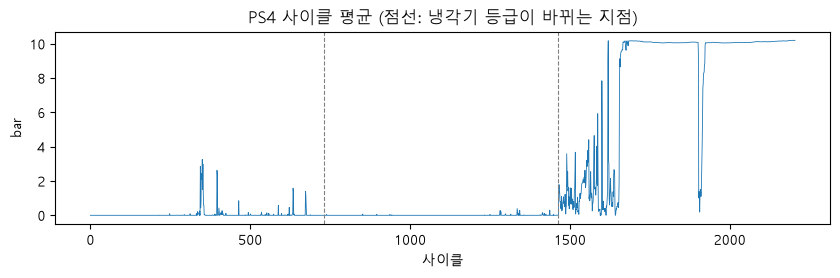

In [9]:
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(raw["PS4"].mean(1), lw=0.6)
for s in [732, 1464]:
    ax.axvline(s, color="gray", ls="--", lw=0.8)
ax.set(title="PS4 사이클 평균 (점선: 냉각기 등급이 바뀌는 지점)", xlabel="사이클", ylabel="bar")
plt.show()

**해석**: PS4가 전부 0인 사이클은 냉각기 3%·20% 구간에만 있고 100% 구간에는 하나도 없습니다. 그대로 두면 모델이 "PS4=0이면 냉각기 불량"이라는, 실제 고장과 상관없는 규칙을 배웁니다(**정답 누수**).

### 4-2. FS1: 포화 후보

최댓값이 같은 값으로 반복되고 그보다 큰 값이 없으면 포화 후보입니다(G-1 2일차).

In [10]:
fs1 = raw["FS1"]
FS1_SAT = fs1.max()
hit = np.isclose(fs1, FS1_SAT)
print(f"최댓값 {FS1_SAT}: 샘플 {hit.sum()}개, 사이클 {hit.any(1).sum()}개")
print("최댓값이 나온 시점(초):", sorted(set(np.where(hit)[1] / 10)))
print("사이클별 최댓값 분포:", pd.Series(fs1.max(1)).describe().round(2).to_dict())

최댓값 20.479: 샘플 1049개, 사이클 1002개
최댓값이 나온 시점(초): [np.float64(9.5), np.float64(9.6), np.float64(9.7), np.float64(9.8), np.float64(49.1)]
사이클별 최댓값 분포: {'count': 2205.0, 'mean': 20.13, 'std': 0.45, 'min': 18.7, '25%': 19.88, '50%': 20.36, '75%': 20.48, 'max': 20.48}


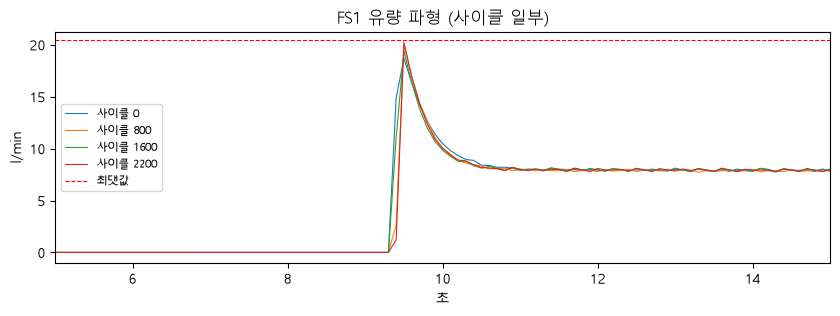

In [11]:
fig, ax = plt.subplots(figsize=(10, 3))
t = np.arange(600) / 10
for c in [0, 800, 1600, 2200]:
    ax.plot(t, fs1[c], lw=0.8, label=f"사이클 {c}")
ax.axhline(FS1_SAT, color="red", ls="--", lw=0.8, label="최댓값")
ax.set(title="FS1 유량 파형 (사이클 일부)", xlabel="초", ylabel="l/min", xlim=(5, 15))
ax.legend(fontsize=8)
plt.show()

### 4-3. SE: 매 사이클 앞 8초의 0

In [12]:
se = raw["SE"]
zero_cols = sorted(set(np.where(se == 0)[1]))
print("0이 나오는 시점(초):", zero_cols)
print("0이 있는 사이클 수:", (se == 0).any(1).sum(), "/", len(se))
pd.DataFrame(se[:3, :10], columns=[f"{s}초" for s in range(10)])

0이 나오는 시점(초): [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
0이 있는 사이클 수: 2205 / 2205


,0초,1초,2초,3초,4초,5초,6초,7초,8초,9초
0,68.039,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69.141
1,68.264,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,65.715
2,68.595,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,67.320


**해석**: 0초에는 값이 있고 1\~8초만 0입니다. 효율 계수를 계산할 데이터가 아직 쌓이지 않은 구간으로 보입니다. 그대로 평균을 내면 `SE_mean`이 낮게 끌려가고 `SE_min`은 항상 0이 됩니다.

### 4-4. CE·CP: 가상 센서(파생값)

설명서에 "virtual"로 적힌 센서입니다. 실제로 재는 값이 아니라 다른 값으로 계산한 값입니다(G-1 2일차 센서 카드: 직접 측정인지 파생값인지 적습니다).

In [13]:
pd.DataFrame({"CE 사이클 평균": raw["CE"].mean(1), "냉각기 등급": labels["cooler_pct"]}) \
    .groupby("냉각기 등급")["CE 사이클 평균"].agg(["mean", "min", "max"]).round(1)

,mean,min,max
냉각기 등급,,,
3,19.6,17.6,39.6
20,27.2,22.8,28.3
100,46.9,35.7,47.9


### 4-5. 안정 플래그와 사이클 순서

`stable_flag`=1은 "아직 안정 상태에 도달하지 않았을 수 있음"입니다. G-1 3절의 "그 구간에 조업이 있었는가"처럼 정상 조업 구간을 고를 때 씁니다.

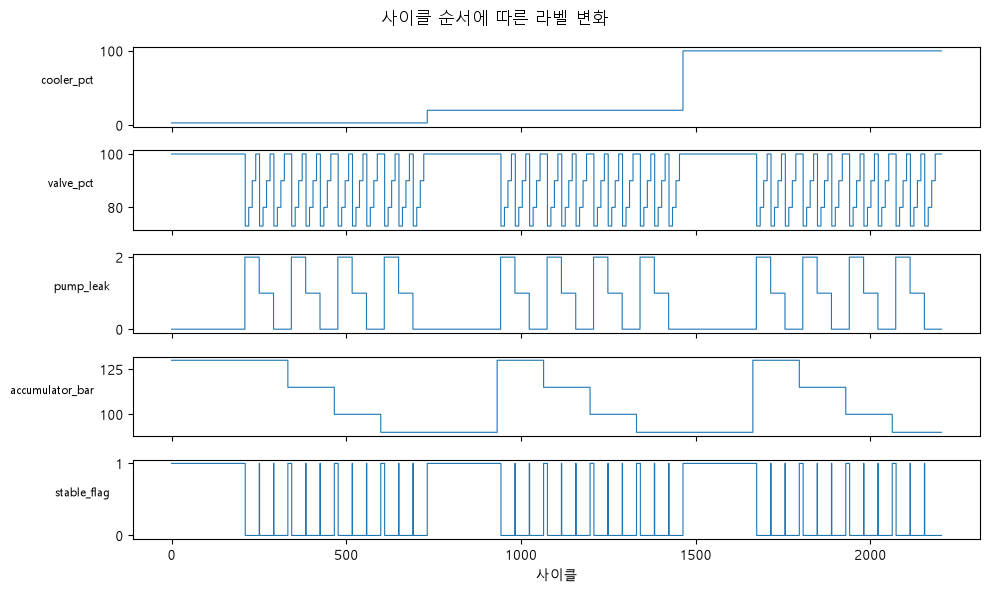

안정(0) 사이클: 1449
네 부품 모두 정상: 21 | 그중 안정: 10


In [14]:
fig, axes = plt.subplots(5, 1, figsize=(10, 6), sharex=True)
for ax, c in zip(axes, LABELS):
    ax.plot(labels[c], lw=0.8, drawstyle="steps-post")
    ax.set_ylabel(c, rotation=0, ha="right", fontsize=8)
axes[-1].set_xlabel("사이클")
fig.suptitle("사이클 순서에 따른 라벨 변화")
plt.tight_layout()
plt.show()

all_normal = (labels.cooler_pct == 100) & (labels.valve_pct == 100) & (labels.pump_leak == 0) & (labels.accumulator_bar == 130)
print("안정(0) 사이클:", (labels.stable_flag == 0).sum())
print("네 부품 모두 정상:", all_normal.sum(), "| 그중 안정:", (all_normal & (labels.stable_flag == 0)).sum())

**해석**: 냉각기 등급은 3개 블록으로만 바뀌고, 각 블록 시작 직후 211사이클은 불안정 상태입니다. 학습·평가 데이터를 나눌 때 이 순서 효과를 점검해야 합니다. 이 노트북은 안정 구간을 **표시만** 하고 빼지는 않습니다(`stable_flag` 컬럼 유지). 어느 단계에서 뺄지는 분석 담당자가 정합니다.

## 5. 처리 (초안)

4절에서 찾은 문제를 처리합니다. 원본 `raw`는 그대로 두고 복사본 `clean`을 고칩니다(G-1 3절: 원본은 그대로).

**각 셀의 [검토] 항목을 보고 처리 방식을 정해 주세요.**

In [15]:
clean = {k: v.astype(float).copy() for k, v in raw.items()}

### 5-1. PS4: 60초 내내 0인 사이클을 NaN으로

**[검토]**
- 셋 중 하나를 고릅니다. NaN으로 둘지(현재), PS4 센서를 아예 뺄지, 해당 사이클을 뺄지.
- 정상 사이클 안의 0(약 24%)은 실제 저압 구간일 수 있어 그대로 두었습니다. 맞는지 파형으로 확인해 주세요.
- NaN으로 두면 RandomForest 학습 전에 채우거나 컬럼을 빼야 합니다. 냉각기 모델에서는 PS4를 빼는 것을 우선 검토합니다.

In [16]:
clean["PS4"][ps4_dead] = np.nan
print("NaN으로 바꾼 사이클:", ps4_dead.sum())

NaN으로 바꾼 사이클: 1238


### 5-2. SE: 1\~8초의 0을 NaN으로

**[검토]** 그냥 NaN으로 둘지(현재), 9초 이후만 쓰도록 잘라낼지 정합니다. 결과는 같고, 표현 방식만 다릅니다.

In [17]:
head = clean["SE"][:, 1:9]
print("NaN으로 바꾼 값:", (head == 0).sum())
head[head == 0] = np.nan  # head는 clean["SE"]의 일부를 가리키므로 clean["SE"]가 바뀝니다

NaN으로 바꾼 값: 17640


### 5-3. FS1: 값은 두고 포화 횟수를 기록

G-1 2일차의 원칙대로, 포화 구간은 따로 표시하고 실제 크기 대신 포화가 일어났다는 사실을 씁니다.

**[검토]** `FS1_max`를 특징에서 뺄지, `clip`이나 NaN으로 처리할지 정합니다.

In [18]:
fs1_sat_n = np.isclose(clean["FS1"], FS1_SAT).sum(1)
print("포화가 있는 사이클:", (fs1_sat_n > 0).sum())

포화가 있는 사이클: 1002


## 6. 특징 추출: 사이클별 통계

모델은 **1행 = 1사이클** 형태의 표가 필요합니다. 센서마다 60초 동안의 평균·표준편차·최솟값·최댓값을 계산합니다. NaN은 빼고 계산합니다(`np.nan*` 함수).

**[검토]** 4가지 통계만으로는 파형의 모양과 타이밍 정보가 사라집니다. 성능이 부족하면 구간별 평균 같은 특징을 추가합니다(G-1 기준 강의 밖).

In [19]:
import warnings

feats = {}
with warnings.catch_warnings():  # PS4처럼 전부 NaN인 사이클은 결과도 NaN (경고만 숨김)
    warnings.simplefilter("ignore", RuntimeWarning)
    for name, m in clean.items():
        if name == "FS1":
            feats["FS1_sat_n"] = fs1_sat_n  # 5-3에서 센 포화 횟수
        feats[f"{name}_mean"] = np.nanmean(m, 1)
        feats[f"{name}_std"] = np.nanstd(m, 1)
        feats[f"{name}_min"] = np.nanmin(m, 1)
        feats[f"{name}_max"] = np.nanmax(m, 1)

cyc = pd.DataFrame(feats, index=labels.index).join(labels)
print(cyc.shape)
cyc.head()

(2205, 74)


,PS1_mean,PS1_std,PS1_min,PS1_max,PS2_mean,PS2_std,PS2_min,PS2_max,PS3_mean,PS3_std,PS3_min,PS3_max,PS4_mean,PS4_std,PS4_min,...,CE_min,CE_max,CP_mean,CP_std,CP_min,CP_max,SE_mean,SE_std,SE_min,SE_max,cooler_pct,valve_pct,pump_leak,accumulator_bar,stable_flag
cycle,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,160.673492,13.938147,145.83,191.51,109.466914,47.110581,0.0,156.99,1.991475,0.945626,0.0,10.039,NaN,NaN,NaN,...,28.866,47.438,1.862750,0.277047,1.383,2.188,68.258288,4.418372,54.079,79.568,3,100,0,130,1
1,160.603320,14.117791,145.73,191.47,109.354890,47.041690,0.0,157.56,1.976234,0.941889,0.0,9.992,NaN,NaN,NaN,...,23.320,29.208,1.255550,0.073981,1.147,1.414,68.464173,4.565556,54.092,80.441,3,100,0,130,1
2,160.347720,14.191436,145.37,191.41,109.158845,46.988144,0.0,156.97,1.972224,0.943422,0.0,10.914,NaN,NaN,NaN,...,21.220,23.554,1.113217,0.023069,1.076,1.159,68.703635,4.473670,54.786,80.824,3,100,0,130,1
3,160.188088,14.226617,145.14,191.34,109.064807,46.968307,0.0,156.44,1.946576,0.935456,0.0,10.297,NaN,NaN,NaN,...,19.673,21.565,1.062150,0.024415,1.022,1.107,68.994115,4.483325,54.780,80.930,3,100,0,130,1
4,160.000472,14.275244,144.95,191.41,108.931434,46.871040,0.0,158.13,1.922707,0.930258,0.0,11.102,NaN,NaN,NaN,...,19.133,20.460,1.070467,0.021297,1.016,1.106,68.602231,4.952426,54.451,81.100,3,100,0,130,1


## 7. 검증

In [20]:
assert len(cyc) == len(labels) == 2205, "사이클 수가 맞지 않습니다"
assert cyc[LABELS].isna().sum().sum() == 0, "라벨에 결측이 있으면 안 됩니다"

na = cyc.isna().sum()
print("NaN이 있는 컬럼 (의도한 것만 있어야 함):")
print(na[na > 0])
print("\nSE_mean 평균: 처리 전", round(raw["SE"].mean(1).mean(), 2), "-> 처리 후", round(cyc["SE_mean"].mean(), 2))

NaN이 있는 컬럼 (의도한 것만 있어야 함):
PS4_mean    1238
PS4_std     1238
PS4_min     1238
PS4_max     1238
dtype: int64

SE_mean 평균: 처리 전 55.29 -> 처리 후 63.79


## 8. 저장

- `hyd_cycles.csv`: 메인 분석 데이터 (저장소에 포함)
- `hyd_sensors.csv`: 센서 사전과 품질 메모 (저장소에 포함)
- `hyd_1hz.csv`: 1초 단위 시계열 (17MB, 저장소 제외). 파형을 볼 때만 필요하므로 `SAVE_1HZ = True`일 때만 저장합니다.

In [21]:
cyc.to_csv(OUT / "hyd_cycles.csv", float_format="%.5g")

NOTES = {
    "PS4": "1,238사이클 전부 0(위장 결측) → NaN. 냉각기 3%·20% 구간에만 있음(누수 주의)",
    "FS1": "최댓값 20.479 반복(포화 후보, 약 9.5초 부근) → FS1_sat_n 기록, FS1_max 신뢰 낮음",
    "SE": "매 사이클 1~8초가 0 → NaN, 통계는 나머지 52초",
    "CE": "가상 센서(파생값). 냉각기 등급과 거의 그대로 대응",
    "CP": "가상 센서(파생값)",
}
pd.DataFrame([(k, *v, NOTES.get(k, "")) for k, v in SENSORS.items()],
             columns=["sensor", "quantity", "unit", "sampling_hz", "note"]) \
    .to_csv(OUT / "hyd_sensors.csv", index=False, encoding="utf-8-sig")
print("저장:", OUT / "hyd_cycles.csv", cyc.shape)

저장: C:\Gorosteel\data\processed\hyd_cycles.csv (2205, 74)


In [22]:
SAVE_1HZ = False  # 1초 단위 시계열이 필요하면 True로 바꿔 실행

if SAVE_1HZ:
    n = len(labels)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        onehz = {k: np.nanmean(m.reshape(n, 60, SENSORS[k][2]), 2).ravel() for k, m in clean.items()}
    ts = pd.DataFrame(onehz)
    ts.insert(0, "second", np.tile(np.arange(60), n))
    ts.insert(0, "cycle", np.repeat(np.arange(n), 60))
    ts = ts.merge(labels.reset_index(), on="cycle")
    ts.to_csv(OUT / "hyd_1hz.csv", index=False, float_format="%.5g")
    print("저장:", OUT / "hyd_1hz.csv", ts.shape)

## 담당자 검토 목록

- [ ] 5-1 PS4 처리 방식 (NaN / 센서 제외 / 사이클 제외)
- [ ] 5-2 SE 앞 8초 처리 방식
- [ ] 5-3 FS1 포화: `FS1_max`를 쓸지
- [ ] 안정 구간(`stable_flag`=1)을 어느 단계에서 뺄지
- [ ] 6 특징 추출: 4가지 통계로 충분한지
- [ ] 센서 카드 작성 (G-1 2일차): 태그, 물리량·단위, 샘플링, 범위·포화, 분해능, 파생값 여부

처리 방식을 바꾸면 루트 README 4절의 "원본 데이터의 함정" 표도 함께 고쳐 주세요.